_ExplainDB — Copyright (C) 2026 Prof. Dr. Jens Dittrich, Saarland University._  
_Licensed under the GNU Affero General Public License v3 (AGPL-3.0). See the `LICENSE` file._

In [1]:
import sys, pathlib

# Put the repo root (the directory containing `system/`) on sys.path so
# `from system...` works whether this notebook is opened from its own
# folder or from the repo root.
for _p in (pathlib.Path.cwd(), *pathlib.Path.cwd().parents):
    if (_p / "system").is_dir():
        if str(_p) not in sys.path:
            sys.path.insert(0, str(_p))
        break

# RAID Nesting Trade-offs

A **RAID 0** array stripes data over its members. A member can be a device or
itself a RAID 0 array, so arrays can be *nested*. This notebook asks two
questions about **sequential read performance**:

1. Given a fixed number of **identical** devices, does it matter whether we
   stripe over all of them in one flat RAID 0 or nest RAID 0 arrays?
2. Given devices of **different speed**, can nesting help?

We answer both with the cost model in `system/storage/RAID/cost_model.py`.

In [2]:
from system.storage.RAID.cost_model import Device, RAID_0
from system.storage.RAID.nesting import (
    arrangements_of_mixed_devices,
    build_nested_raid_0,
    count_devices,
    factorisations,
)

## The cost model, briefly

In the first part, every device is identical, with a sequential read
performance of **100 MB/s**:

In [3]:
def make_device() -> Device:
    """A single identical device: 100 MB/s sequential read/write, 1000 IOPS."""
    return Device(100, 100, 1000, 1000)


make_device().get_sequential_read_performance()

100

For a RAID 0 array, the model defines the **sequential read performance** as

$$\text{read}(\text{RAID 0}) = \min_{m \in \text{members}} \text{read}(m)\; \times\; |\text{members}|,$$

i.e. the slowest member throttles the stripe, multiplied by the number of
members (see `RAID_0.get_sequential_read_performance`). Keep this formula in
mind — it explains everything below.

## Part 1: identical devices

We look at nestings in which all members of a level are built alike. Such a
nesting of $k$ devices is described by a **factorisation** of $k$ into
factors $\ge 2$, e.g. $32 = 4 \cdot 2 \cdot 4$. Each factor is one level of the
nesting, outermost first: the outermost RAID 0 has 4 members, each of them a
RAID 0 with 2 members, each of them a RAID 0 over 4 devices, so
$4 \cdot 2 \cdot 4 = 32$ devices in all. `factorisations` yields every
factorisation except the trivial $[k]$, which is the flat stripe itself, and
`build_nested_raid_0` builds the nesting (both in
`system/storage/RAID/nesting.py`).

In [4]:
import pandas as pd

NUMBER_OF_DEVICES = 32

rows: list[dict[str, object]] = []
# fewer levels first, then by the factors:
for config in sorted(factorisations(NUMBER_OF_DEVICES), key=lambda c: (len(c), c)):
    raid = build_nested_raid_0(config, make_device)
    rows.append(
        {
            "nesting": " × ".join(map(str, config)),
            "levels": len(config),
            "devices": count_devices(raid),
            "seq_read_MB_s": raid.get_sequential_read_performance(),
        }
    )

nestings = pd.DataFrame(rows)
nestings

,nesting,levels,devices,seq_read_MB_s
0,2 × 16,2,32,3200
1,4 × 8,2,32,3200
2,8 × 4,2,32,3200
3,16 × 2,2,32,3200
4,2 × 2 × 8,3,32,3200
5,2 × 4 × 4,3,32,3200
6,2 × 8 × 2,3,32,3200
7,4 × 2 × 4,3,32,3200
8,4 × 4 × 2,3,32,3200
9,8 × 2 × 2,3,32,3200


## What the numbers say

Every nesting uses all 32 devices and reaches **3200 MB/s**, the raw total of
$32 \times 100$ MB/s. The formula explains why: when all $m$ members of a RAID 0
are equally fast, the minimum is the speed of any one member, so the array is
$m$ times as fast as one member. Level by level, a nesting $a \cdot b \cdot c$
therefore reads $a \cdot b \cdot c \times 100$ MB/s, exactly as much as one
flat stripe over the same devices:

In [5]:
# All nestings ...
print(
    f"nestings of {NUMBER_OF_DEVICES}:  {nestings['seq_read_MB_s'].min()} to "
    f"{nestings['seq_read_MB_s'].max()} MB/s"
)
# ... versus simply striping all devices in one flat RAID 0.
flat = RAID_0([make_device() for _ in range(NUMBER_OF_DEVICES)])
print(
    f"flat RAID 0 of {NUMBER_OF_DEVICES}: {flat.get_sequential_read_performance()} MB/s"
)

nestings of 32:  3200 to 3200 MB/s
flat RAID 0 of 32: 3200 MB/s


## Part 2: devices of different speed

Now take **four slow** devices (100 MB/s, as above) and **two fast** ones
(200 MB/s). In one flat stripe over all six, the slowest device sets the pace
for every member: $100 \times 6 = 600$ MB/s, and the fast devices waste half
their speed. Nesting lets us **group the devices by speed**: one RAID 0 of the
four slow devices (400 MB/s) and one RAID 0 of the two fast devices (400 MB/s),
striped together, read $400 \times 2 = 800$ MB/s. This works because both
groups are equally fast. If every group is a flat stripe that contains a slow
device, the slow devices throttle each group again: the nesting can at best
match the flat stripe, and it falls below it when the groups differ in size, as
in the third arrangement below.

In [6]:
def make_fast_device() -> Device:
    """A fast device: 200 MB/s sequential read/write, 2000 IOPS."""
    return Device(200, 200, 2000, 2000)


# the same four slow and two fast devices, arranged in three ways:
arrangements = arrangements_of_mixed_devices(make_device, make_fast_device)
mixed = pd.DataFrame(
    [
        {
            "arrangement": name,
            "devices": count_devices(raid),
            "seq_read_MB_s": raid.get_sequential_read_performance(),
        }
        for name, raid in arrangements.items()
    ]
)
mixed

,arrangement,devices,seq_read_MB_s
0,flat,6,600
1,grouped by speed,6,800
2,mixed groups,6,400


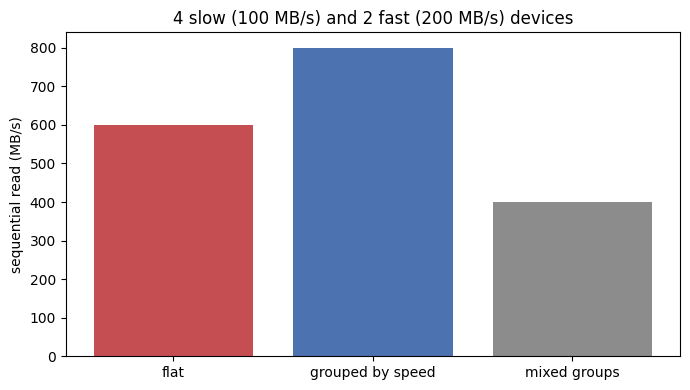

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    mixed["arrangement"],
    mixed["seq_read_MB_s"],
    color=["#C44E52", "#4C72B0", "#8C8C8C"],
)
ax.set_ylabel("sequential read (MB/s)")
ax.set_title("4 slow (100 MB/s) and 2 fast (200 MB/s) devices")
fig.tight_layout()
plt.show()

## Takeaway

For **identical devices**, a RAID 0 nesting whose members of a level are alike
reads exactly as fast as one flat stripe over the same devices: such a nesting
neither helps nor hurts sequential reads, so the flat stripe is the simpler
choice. Members of unequal size do hurt, even with identical devices: a RAID 0
of a stripe of three devices and a fourth device reads
$\min(300, 100) \times 2 = 200$ MB/s, half as much as the flat stripe of four.

For **devices of different speed**, nesting can help: grouping the devices into
equally fast members stops the slowest device from throttling the whole stripe.
A grouping with unequal members, however, can be worse than the flat stripe.
Other reasons to nest come from other RAID levels: a RAID 1 mirror or a parity
level adds **resilience**, at the cost of throughput or capacity.